# Cold campaign: frequency dependence and parameter map

Equivalents of **all six paper figures** for Luka's $T=0.1\,\mathrm{K}$ campaign. Plot conventions follow `figure3.ipynb`, `figure6.ipynb`, and the PDFs in `latex/arXiv-version`; the original notebooks are unchanged.

We use $\omega=\pi/(2\tau)$ in rad/s and average the **absolute** staggered charge order over realizations:
$\langle|\kappa|\rangle=\langle|\sum_{ij}(-1)^{i+j}q_{ij}|\rangle/(4N)$, with $N=10^2$ vertices.
The paper's label $\langle\kappa\rangle$ denotes this quantity. $P(v)$ groups the six saved classes by $|q|$.

These are final **retained** frames, at $t=\tau-0.05$ s (20 fps), matching the campaign's cleaning convention. The sampled times are 1–20, 30, 40, 50, 70, 80, 90, and 100 s; there is no 60 or 1000 s run. Noise temperature is 0.1 K, with mobility held at its original reference value. Saved CSV summaries supply vertex statistics and charge order. Parquet trajectories supply motion observables and snapshots; cached reductions are saved alongside the figures. Fig. 1 reuses the original, temperature-independent setup artwork.

In [1]:
from pathlib import Path
import json
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/frequencygs-matplotlib")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_ROOT = Path("/run/media/holo/aura/BIG/reentrancy/test11_0p1K_20261009/campaigns")
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/notebooks").is_dir())
FIGURE_ROOT = REPO / "data/figures/cold-0p1K"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
SIZE = 10
FIELD = 20  # Fig. 3 cut, in mT
FIG3_XLIM = (0, 0.4)
FIG6_XLIM = (None, 0.3)  # None starts at the lowest sampled frequency

plt.rcParams.update({
    "pgf.texsystem": "pdflatex", "font.family": "serif",
    "text.usetex": True, "pgf.rcfonts": False,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "axes.labelsize": 10,
})
CHARGE_COLORS = ["#191970", "#6495ed", "#cd853f"]

## Saved data and provenance
The four campaign directories remain separate. Each rotation-time pack has its own summaries. The table below checks the campaign temperature, size, sampling rate, and completion records before loading them.

In [2]:
campaigns = sorted(p for p in DATA_ROOT.glob("luka-cold-*") if p.is_dir())
provenance = []
for campaign in campaigns:
    settings = json.loads((campaign / "campaign.json").read_text())
    records = json.loads((campaign / "resources.json").read_text())
    assert settings["temperature"] == 0.1 and settings["size"] == SIZE
    assert settings["framerate"] == 20 and settings["realizations"] == 10
    assert all(r["returncode"] == 0 for r in records)
    provenance.append({"campaign": campaign.name, "temperature_K": settings["temperature"],
                       "fps": settings["framerate"], "tau_s": settings["times"]})
assert len(campaigns) == 4
count_files = sorted(DATA_ROOT.glob(f"*/test11_improved/{SIZE}/*/average_counts.csv"))
kappa_files = sorted(DATA_ROOT.glob(f"*/test11_improved/{SIZE}/*/kappa_all.csv"))
assert len(count_files) == len(kappa_files) == 27
display(pd.DataFrame(provenance))
print("Example summaries:", count_files[0], kappa_files[0], sep="\n")
display(pd.read_csv(count_files[0], nrows=3))
display(pd.read_csv(kappa_files[0], nrows=3))

Example summaries:
/run/media/holo/aura/BIG/reentrancy/test11_0p1K_20261009/campaigns/luka-cold-tau1-10-20261006/test11_improved/10/1.0/average_counts.csv
/run/media/holo/aura/BIG/reentrancy/test11_0p1K_20261009/campaigns/luka-cold-tau1-10-20261006/test11_improved/10/1.0/kappa_all.csv


,campaign,temperature_K,fps,tau_s
0,luka-cold-tau1-10-20261006,0.1,20,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
1,luka-cold-tau11-20-20261007,0.1,20,"[11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18...."
2,luka-cold-tau30-40-50-70-20261007,0.1,20,"[30.0, 40.0, 50.0, 70.0]"
3,luka-cold-tau80-90-100-20261008,0.1,20,"[80.0, 90.0, 100.0]"


,time,field,total_time,I,II,III,IV,V,VI
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,2.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


,realization,t,kappa,field,total_time
0,1,0.00,0.0,0.0,1.0
1,1,0.05,0.0,0.0,1.0
2,1,0.10,0.0,0.0,1.0


## Final-frame reduction
Select the largest saved time separately for every field and realization. Take the absolute value **before** averaging, and normalize once by $4N=400$. The vertex fractions already average over realizations. Frequencies are not rounded or interpolated.

In [3]:
def final_rows(path, keys, time_column):
    # Keep only endpoints while reading; do not concatenate complete time series.
    tails = []
    for chunk in pd.read_csv(path, chunksize=100_000):
        tails.append(chunk.loc[chunk.groupby(keys)[time_column].idxmax()])
    endpoints = pd.concat(tails, ignore_index=True)
    return endpoints.loc[endpoints.groupby(keys)[time_column].idxmax()].copy()

counts = pd.concat([final_rows(p, ["total_time", "field"], "time")
                    for p in count_files], ignore_index=True)
kappa_last = pd.concat([final_rows(p, ["total_time", "field", "realization"], "t")
                        for p in kappa_files], ignore_index=True)
assert not counts.duplicated(["total_time", "field"]).any()
assert not kappa_last.duplicated(["total_time", "field", "realization"]).any()
assert np.allclose(counts["time"], counts["total_time"] - 0.05)
assert np.allclose(kappa_last["t"], kappa_last["total_time"] - 0.05)
assert np.allclose(counts[["I", "II", "III", "IV", "V", "VI"]].sum(axis=1), 1)
kappa_last["order"] = kappa_last["kappa"].abs() / (4 * SIZE**2)
order = kappa_last.groupby(["total_time", "field"]).agg(
    kappa=("order", "mean"), kappa_std=("order", "std"),
    realizations=("order", "size"), t=("t", "first")).reset_index()
assert (order["realizations"] == 10).all()
final = counts.merge(order, on=["total_time", "field"], validate="one_to_one")
final["omega"] = np.pi / (2 * final["total_time"])
final["P4"] = final["I"] + final["VI"]
final["P2"] = final["II"] + final["V"]
final["P0"] = final["III"] + final["IV"]
assert len(final) == 27 * 21 and np.isfinite(final.select_dtypes("number")).all().all()
assert final["kappa"].between(0, 1).all()
final = final.sort_values(["field", "omega"]).reset_index(drop=True)
final.to_csv(FIGURE_ROOT / "final_observables.csv", index=False)
display(final.query("field == @FIELD")[["total_time", "omega", "time", "P4", "P2", "P0", "kappa", "kappa_std"]])

,total_time,omega,time,P4,P2,P0,kappa,kappa_std
540,100.0,0.015708,99.95,0.378,0.432,0.190,0.312,0.042111
541,90.0,0.017453,89.95,0.379,0.450,0.171,0.290,0.080277
542,80.0,0.019635,79.95,0.376,0.484,0.140,0.419,0.067239
543,70.0,0.022440,69.95,0.412,0.474,0.114,0.550,0.049889
544,50.0,0.031416,49.95,0.630,0.332,0.038,0.794,0.029136
545,40.0,0.039270,39.95,0.888,0.108,0.004,0.942,0.019322
546,30.0,0.052360,29.95,1.000,0.000,0.000,1.000,0.000000
547,20.0,0.078540,19.95,1.000,0.000,0.000,1.000,0.000000
548,19.0,0.082673,18.95,1.000,0.000,0.000,1.000,0.000000
549,18.0,0.087266,17.95,1.000,0.000,0.000,1.000,0.000000


In [4]:
import sys
import shutil
import subprocess
import matplotlib as mpl
from matplotlib import patches
import pyarrow.parquet as pq
from IPython.display import Image

sys.path.insert(0, str(REPO / "src/py"))
from cold_figure_analysis import motion_series, snapshot, activity_widths

PAPER_ROOT = REPO.parent / "latex/arXiv-version"
SELECTED_TIMES = [100, 70, 40, 30, 20, 10, 7, 6, 5, 4]
TRAP_SEP = 10  # micrometres, checked against the pack manifest below
example_pack = count_files[0].parent / f"{FIELD}mT"
manifest = json.loads(next(example_pack.glob("*.manifest.json")).read_text())
assert manifest["realizations"][0]["parameters"]["trap_sep"]["value"] == TRAP_SEP
FREQUENCY_NORM = mpl.colors.Normalize(0, 0.4)
FREQUENCY_CMAP = plt.get_cmap("RdYlGn")

def save_figure(fig, stem):
    for suffix in ["pdf", "png"]:
        fig.savefig(FIGURE_ROOT / f"{stem}.{suffix}", dpi=300, bbox_inches="tight")

## Fig. 1: simulation setup
This schematic and its magic-angle relation do not depend on temperature. Reuse the paper PDF unchanged, rather than redraw its artwork. It is explicitly marked as reused in the output provenance.

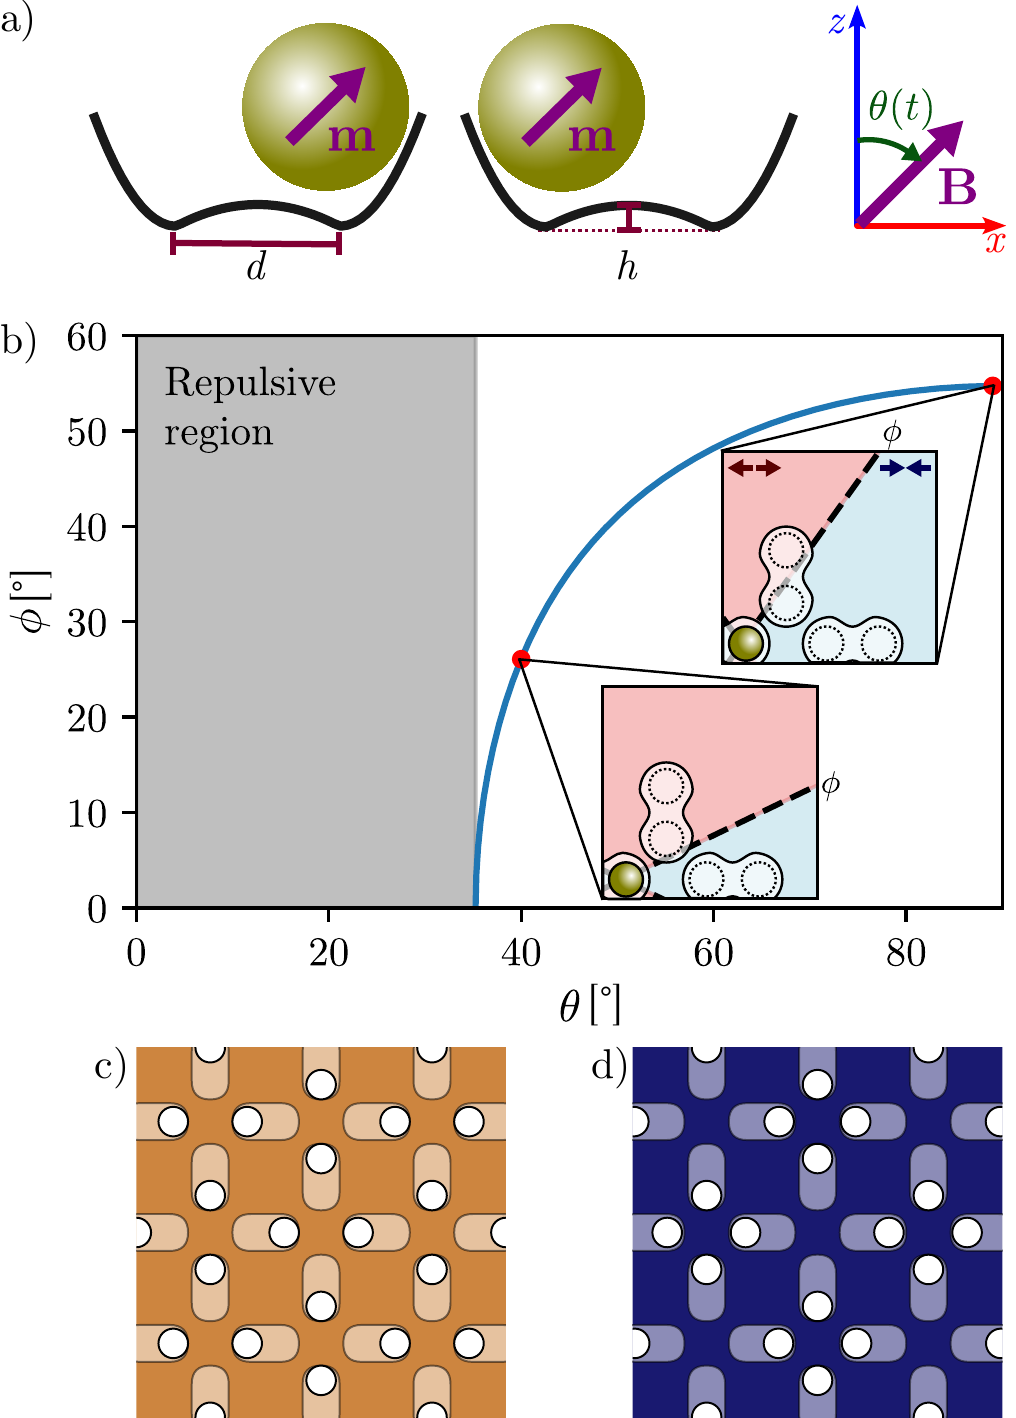

In [5]:
shutil.copy2(PAPER_ROOT / "fig1.pdf", FIGURE_ROOT / "fig1_0p1K.pdf")
subprocess.run(["pdftoppm", "-r", "300", "-singlefile", "-png",
                str(PAPER_ROOT / "fig1.pdf"), str(FIGURE_ROOT / "fig1_0p1K")], check=True)
display(Image(filename=str(FIGURE_ROOT / "fig1_0p1K.png"), width=600))

## Fig. 2: vertex fractions during the rotation
The same 10 and 20 mT columns, charge-class row colors, and `RdYlGn` frequency scale as the paper. The six vertex icons use the saved I–VI charge convention. `SELECTED_TIMES` controls the curves in Figs. 2, 4, and 5; the legend scale remains 0–0.4 rad/s.

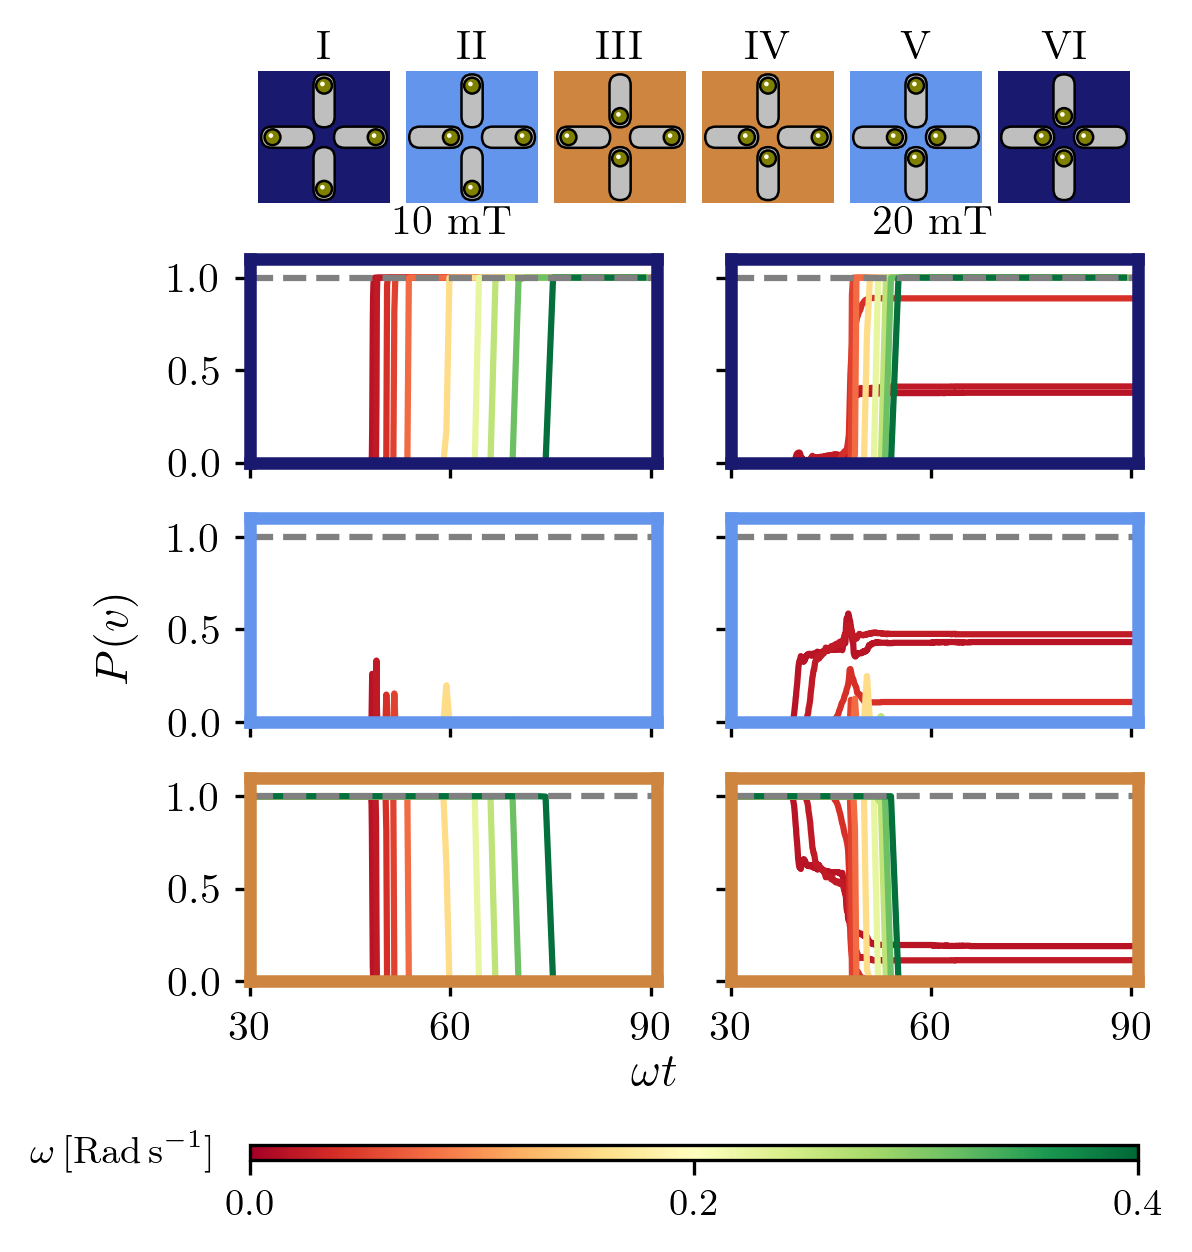

In [6]:
series = pd.concat([pd.read_csv(path).query("field in [10, 20]")
                    for path in count_files], ignore_index=True)
series["theta"] = 90 * series["time"] / series["total_time"]
series["omega"] = np.pi / (2 * series["total_time"])
series["P4"] = series["I"] + series["VI"]
series["P2"] = series["II"] + series["V"]
series["P0"] = series["III"] + series["IV"]

# Four traps around one vertex: left, right, bottom, top. +1 points out.
def vertex_icon(ax, outward, color):
    ax.set_facecolor(color)
    arms = np.array([[-1, 0], [1, 0], [0, -1], [0, 1]])
    for arm, sign in zip(arms, outward):
        center = 0.55 * arm
        horizontal = arm[0] != 0
        width, height = (0.8, 0.32) if horizontal else (0.32, 0.8)
        ax.add_patch(patches.FancyBboxPatch(center-[width/2, height/2], width, height,
            boxstyle="round,pad=0,rounding_size=0.16", facecolor="0.75", edgecolor="k", linewidth=0.6))
        point = center + 0.23*sign*arm
        ax.add_patch(patches.Circle(point, 0.12, facecolor="olive", edgecolor="k", linewidth=0.6))
        ax.add_patch(patches.Circle(point+[-0.025, 0.025], 0.035, facecolor="ivory", edgecolor="none"))
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values(): spine.set_visible(False)

def frequency_colorbar(fig, position):
    cax = fig.add_axes(position)
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=FREQUENCY_NORM, cmap=FREQUENCY_CMAP),
                      cax=cax, orientation="horizontal", ticks=[0, 0.2, 0.4])
    cb.ax.tick_params(labelsize=9)
    cax.text(-0.04, 0.5, r"$\omega\,[\mathrm{Rad}\,\mathrm{s}^{-1}]$",
             transform=cax.transAxes, ha="right", va="center", fontsize=9)


def plot_vertex_evolution(table):
    fig = plt.figure(figsize=((246 + 23.759)/72, 4.1), dpi=300)
    gs = fig.add_gridspec(4, 2, height_ratios=[0.65, 1, 1, 1], hspace=0.3, wspace=0.18)
    icons = gs[0, :].subgridspec(1, 6, wspace=0)
    patterns = [[1,1,1,1], [-1,1,1,1], [1,1,-1,-1], [-1,1,-1,1], [-1,-1,-1,1], [-1,-1,-1,-1]]
    for i, (name, pattern) in enumerate(zip(["I", "II", "III", "IV", "V", "VI"], patterns)):
        ax = fig.add_subplot(icons[0, i])
        vertex_icon(ax, pattern, [CHARGE_COLORS[0], CHARGE_COLORS[1], CHARGE_COLORS[2],
                                 CHARGE_COLORS[2], CHARGE_COLORS[1], CHARGE_COLORS[0]][i])
        ax.set_title(name, fontsize=10, pad=3)
    for row, column in enumerate(["P4", "P2", "P0"]):
        for j, field in enumerate([10, 20]):
            ax = fig.add_subplot(gs[row+1, j])
            for tau in SELECTED_TIMES:
                group = table.query("total_time == @tau and field == @field").sort_values("time")
                ax.plot(group.theta, group[column], color=FREQUENCY_CMAP(FREQUENCY_NORM(np.pi/(2*tau))))
            ax.set_xlim(30, 91); ax.set_ylim(0, 1.1)
            ax.set_xticks([30, 60, 90]); ax.set_yticks([0, 0.5, 1])
            ax.axhline(1, color="gray", linestyle="--")
            ax.tick_params(labelbottom=row == 2, labelleft=j == 0)
            if row == 0: ax.set_title(f"${field}$ mT", fontsize=10)
            # Match the colored row surrounds in the paper.
            for spine in ax.spines.values():
                spine.set_color(CHARGE_COLORS[row]); spine.set_linewidth(3)
    fig.subplots_adjust(left=0.19, right=0.98, bottom=0.2, top=0.94)
    fig.text(0.05, 0.48, r"$P(v)$", rotation=90, va="center", fontsize=11)
    fig.text(0.55, 0.115, r"$\omega t$", ha="center", fontsize=11)
    frequency_colorbar(fig, [0.19, 0.055, 0.79, 0.012])
    return fig

fig2 = plot_vertex_evolution(series)
save_figure(fig2, "fig2_0p1K")
plt.show()

## Configuration snapshots for Fig. 3
Use realization 1 at 20 mT, comparing the slowest available rotation (100 s) with 4 s ($\omega\simeq0.393$ rad/s). The background shows the actual vertex charge classes. Red segments show the range explored along each trap; white circles show the final particle positions. These are examples, not ensemble averages.

In [7]:
def plot_configuration(ax, trajectory, vertices):
    vertices = vertices.copy()
    q = vertices.charge.abs()
    vertices["class"] = np.where(q == 4, 0, np.where(q == 2, 1,
                                 np.where(vertices.dx**2+vertices.dy**2 > 0, 3, 2)))
    grid = vertices.pivot(index="y", columns="x", values="class").sort_index().sort_index(axis=1)
    classes = grid.to_numpy()
    ax.pcolormesh(grid.columns, grid.index, classes, shading="nearest",
                  cmap=mpl.colors.ListedColormap([*CHARGE_COLORS, "tan"]), vmin=-0.5, vmax=3.5)
    for pid, group in trajectory.groupby("id", sort=True):
        group = group.sort_values("frame")
        end = group.iloc[-1]
        horizontal = abs(end.dx) > abs(end.dy)
        width, height = (20, 10) if horizontal else (10, 20)
        ax.add_patch(patches.FancyBboxPatch((end.x-width/2, end.y-height/2), width, height,
            boxstyle="round,pad=0,rounding_size=5", facecolor="0.8", edgecolor="gray", alpha=0.7, linewidth=0.6))
        rel = group.cx if horizontal else group.cy
        x = [end.x+rel.min(), end.x+rel.max()] if horizontal else [end.x, end.x]
        y = [end.y, end.y] if horizontal else [end.y+rel.min(), end.y+rel.max()]
        ax.plot(x, y, color="#aa0000", linewidth=0.5)
        ax.add_patch(patches.Circle((end.x+end.cx, end.y+end.cy), 4, facecolor="white", edgecolor="black", linewidth=0.6))
    ax.set_xlim(-10, 290); ax.set_ylim(-10, 290)
    ax.set_aspect("equal"); ax.axis("off")

snapshots = [snapshot(DATA_ROOT, tau, FIELD) for tau in [100, 4]]

## Fig. 3: final vertex fractions and charge order
The same single-column width, charge colors, dark red order-parameter curve, dashed unity lines, and linear frequency axis as the original notebook. The paper range clips the fastest $\tau=1$–3 s points; all points remain in `final_observables.csv`. No uncertainty bands are drawn, matching the original figure; `kappa_std` stores the realization standard deviation.

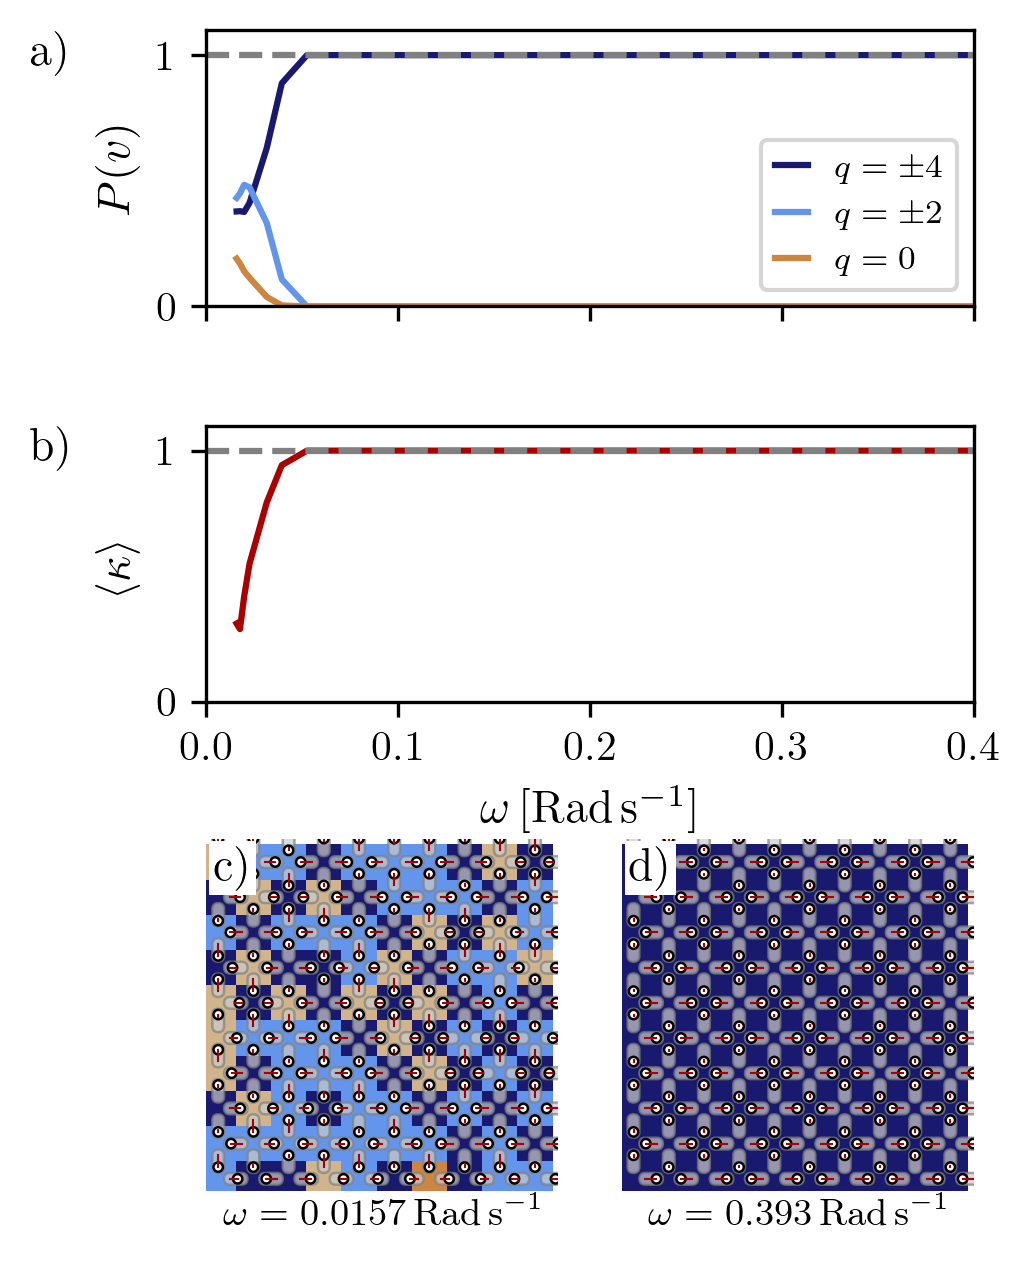

In [8]:
def plot_frequency_dependence(table, field=FIELD):
    cut = table.loc[table["field"] == field].sort_values("omega")
    fig = plt.figure(figsize=((246 + 17.073) / 72, 5.1), dpi=300)
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.4], hspace=0.38, wspace=0.18)
    axes = [fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, :])]
    for column, color, label in zip(["P4", "P2", "P0"], CHARGE_COLORS,
                                   [r"$q=\pm4$", r"$q=\pm2$", r"$q=0$"]):
        axes[0].plot(cut["omega"], cut[column], "-", color=color, label=label)
    axes[0].set_ylabel(r"$P(v)$", fontsize=11)
    axes[0].tick_params(labelbottom=False)
    axes[0].legend(fontsize=8, handlelength=1)
    axes[1].plot(cut["omega"], cut["kappa"], color="#aa0000")
    axes[1].set_ylabel(r"$\langle\kappa\rangle$", fontsize=11)
    axes[1].set_xlabel(r"$\omega\,[\mathrm{Rad}\,\mathrm{s}^{-1}]$", fontsize=11)
    for ax in axes:
        ax.set_xlim(*FIG3_XLIM)
        ax.set_ylim(0, 1.1)
        ax.set_yticks([0, 1])
        ax.axhline(1, color="gray", linestyle="--")
    fig.subplots_adjust(left=0.2)
    for ax, label in zip(axes, ["a)", "b)"]):
        ax.text(-0.23, 1, label, transform=ax.transAxes, va="top", fontsize=11)
    for j, (tau, data) in enumerate(zip([100, 4], snapshots)):
        ax = fig.add_subplot(gs[2, j])
        plot_configuration(ax, *data)
        ax.text(0.02, 0.98, ["c)", "d)"][j], transform=ax.transAxes, va="top", fontsize=11,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
        ax.text(0.5, -0.1, rf"$\omega={np.pi/(2*tau):.3g}\,\mathrm{{Rad}}\,\mathrm{{s}}^{{-1}}$",
                transform=ax.transAxes, ha="center", fontsize=9)
    return fig

fig3 = plot_frequency_dependence(final)
for suffix in ["pdf", "png"]:
    fig3.savefig(FIGURE_ROOT / f"fig3_0p1K_{FIELD}mT.{suffix}",
                 dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()

## Motion reductions for Figs. 4 and 5
$R(0,t)/d$ is the absolute displacement from the initial position projected along each trap, averaged over particles of one orientation and then realizations. This is **not** accumulated path length.

Match `take_distances.py` and `figure4.ipynb`: a particle counts toward $\nu_p$ when its displacement is at least $d/2$. With the initial particles at $\pm d/2$, this is the fraction **currently** across the central hill, not the fraction that ever crossed. The time series may decrease. $\Delta\nu_p$ is the signed difference between successive sampled means, not a derivative or a count of individual crossing events.

The first run reads 270 trajectories at 20 mT. Subsequent runs reuse `motion_20mT.parquet`; its manifest fingerprints the source paths, sizes, modification times, and reduction settings.

In [9]:
motion = motion_series(DATA_ROOT, FIGURE_ROOT, field=FIELD, size=SIZE, trap_sep=TRAP_SEP)
averaged_motion = motion.groupby(["total_time", "t"], as_index=False)[["nu", "Rh", "Rv"]].mean()
averaged_motion["omega"] = np.pi/(2*averaged_motion["total_time"])
averaged_motion["theta"] = 90*averaged_motion["t"]/averaged_motion["total_time"]
assert np.allclose(averaged_motion.query("t == 0")[["nu", "Rh", "Rv"]], 0)
assert motion["nu"].between(0, 1).all()
assert motion.groupby(["total_time", "t"])["realization"].nunique().eq(10).all()
widths = activity_widths(averaged_motion, smooth_window=5, tail_fraction=0.08)
widths.to_csv(FIGURE_ROOT / "activity_widths.csv", index=False)
display(averaged_motion.head())

,total_time,t,nu,Rh,Rv,omega,theta
0,1.0,0.00,0.0,0.000000,0.000000,1.570796,0.0
1,1.0,0.05,0.0,0.023109,0.023029,1.570796,4.5
2,1.0,0.10,0.0,0.040357,0.039667,1.570796,9.0
3,1.0,0.15,0.0,0.054815,0.052428,1.570796,13.5
4,1.0,0.20,0.0,0.067422,0.061777,1.570796,18.0


## Fig. 4: in-trap motion
Top: instantaneous fraction across the hill, with a final-frame frequency cut in the inset. Bottom: horizontal and vertical initial displacements. The inset limits follow the new data, so cold results are not clipped to the old 300 K range.

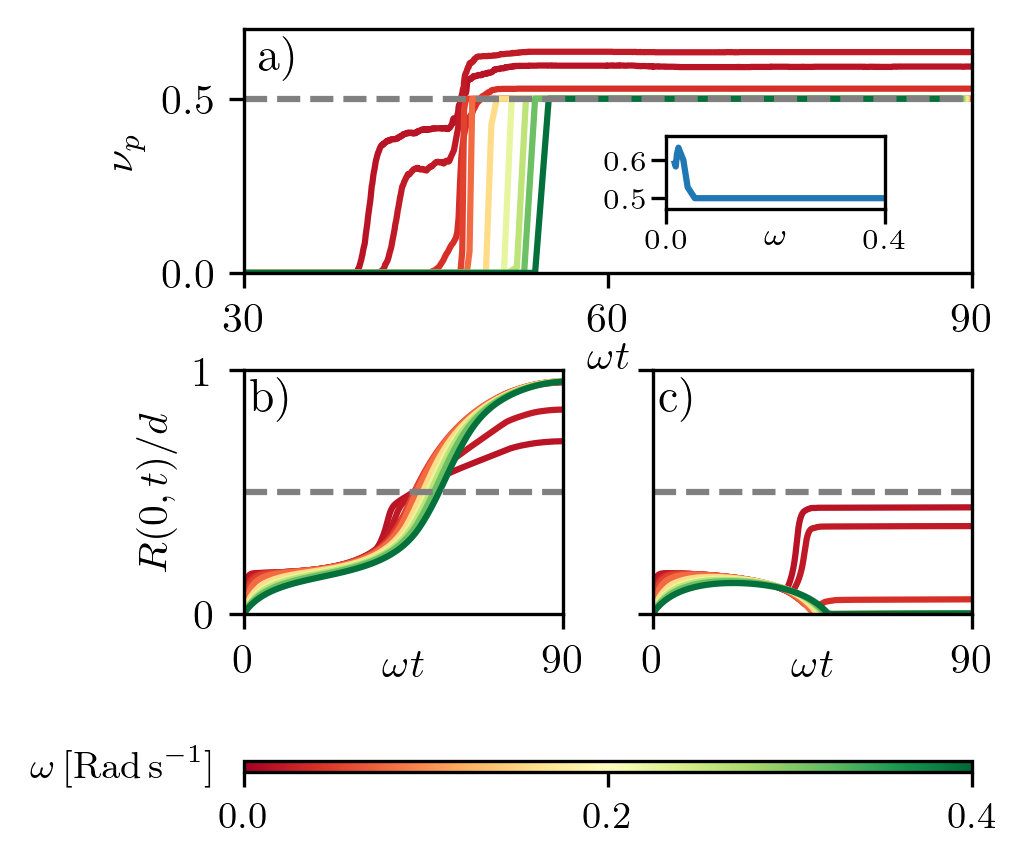

In [10]:
def plot_intrap_motion(table):
    fig = plt.figure(figsize=(246/72+0.052, 3), dpi=300)
    gs = fig.add_gridspec(2, 2, hspace=0.4, wspace=0.28)
    top = fig.add_subplot(gs[0, :])
    horizontal, vertical = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
    for tau in SELECTED_TIMES:
        group = table.query("total_time == @tau").sort_values("t")
        color = FREQUENCY_CMAP(FREQUENCY_NORM(np.pi/(2*tau)))
        top.plot(group.theta, group.nu, color=color)
        horizontal.plot(group.theta, group.Rh, color=color)
        vertical.plot(group.theta, group.Rv, color=color)
    top.axhline(0.5, color="gray", linestyle="--")
    top.set_xlim(30, 90); top.set_xticks([30, 60, 90]); top.set_ylim(0, max(0.7, table.nu.max()+0.05))
    top.set_yticks([0, 0.5])
    top.set_ylabel(r"$\nu_p$"); top.set_xlabel(r"$\omega t$", labelpad=0)
    for ax in [horizontal, vertical]:
        ax.axhline(0.5, color="gray", linestyle="--")
        ax.set_xlim(0, 90); ax.set_ylim(0, 1)
        ax.set_xticks([0, 90]); ax.set_yticks([0, 1]); ax.set_xlabel(r"$\omega t$", labelpad=-8)
    horizontal.set_ylabel(r"$R(0,t)/d$")
    vertical.tick_params(labelleft=False)
    inset = top.inset_axes([0.58, 0.26, 0.3, 0.3])
    endpoints = table.loc[table.groupby("total_time")["t"].idxmax()].sort_values("omega")
    inset.plot(endpoints.omega, endpoints.nu)
    inset.set_xlim(0, 0.4); inset.set_xticks([0, 0.4]); inset.set_xlabel(r"$\omega$", labelpad=-8, fontsize=8)
    visible = endpoints.query("omega <= 0.4").nu
    inset.set_ylim(max(0, visible.min()-0.03), min(1, visible.max()+0.03))
    inset.tick_params(labelsize=7, pad=1)
    for ax, label in zip([top, horizontal, vertical], ["a)", "b)", "c)"]):
        ax.text(0.02, 0.98, label, transform=ax.transAxes, va="top", fontsize=11)
    fig.subplots_adjust(left=0.2, bottom=0.23)
    frequency_colorbar(fig, [0.2, 0.055, 0.7, 0.012])
    return fig

fig4 = plot_intrap_motion(averaged_motion)
save_figure(fig4, "fig4_0p1K")
plt.show()

## Fig. 5: signed flip activity and its angular span
The inset uses the original five-sample moving average of $|\Delta\nu_p|$, with activity defined at 8% of its maximum. The width is the full span between the first and last active midpoint. The smoothing window is in frames, so its angular resolution depends on τ; the cold data use the campaign’s 20 fps.
The main y-axis expands when cold-run peaks exceed the original 0.2 limit.

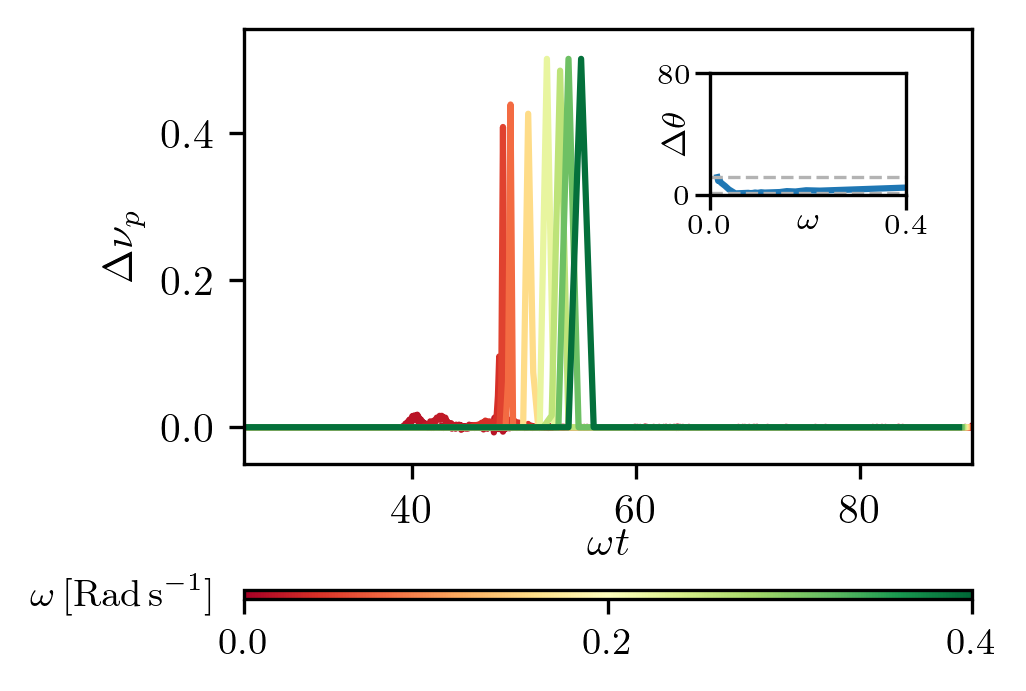

In [11]:
def plot_flip_activity(table, widths):
    fig, ax = plt.subplots(figsize=(246/72+0.05, 2.3), dpi=300)
    for tau in SELECTED_TIMES:
        group = table.query("total_time == @tau").sort_values("t")
        ax.plot(group.theta.to_numpy()[1:], np.diff(group.nu.to_numpy()),
                 color=FREQUENCY_CMAP(FREQUENCY_NORM(np.pi/(2*tau))))
    ax.set_xlim(25, 90)
    peak = max(np.diff(group.sort_values("t").nu.to_numpy()).max()
               for tau, group in table.groupby("total_time") if tau in SELECTED_TIMES)
    ax.set_ylim(-0.05, max(0.2, peak*1.08))
    ax.set_ylabel(r"$\Delta\nu_p$"); ax.set_xlabel(r"$\omega t$", labelpad=-1)
    inset = ax.inset_axes([0.64, 0.62, 0.27, 0.28])
    inset.plot(widths.omega, widths.width_deg)
    visible = widths.query("omega <= 0.4").width_deg
    for value in [visible.min(), visible.max()]:
        inset.axhline(value, color="0.7", linestyle="--", linewidth=0.8)
    inset.set_xlim(0, 0.4); inset.set_ylim(0, max(80, visible.max()*1.05))
    inset.set_xticks([0, 0.4]); inset.set_yticks([0, 80])
    inset.set_xlabel(r"$\omega$", labelpad=-8, fontsize=8)
    inset.set_ylabel(r"$\Delta\theta$", labelpad=-8, fontsize=8)
    inset.tick_params(labelsize=7, pad=1)
    fig.subplots_adjust(left=0.2, bottom=0.25)
    frequency_colorbar(fig, [0.2, 0.055, 0.7, 0.012])
    return fig

fig5 = plot_flip_activity(averaged_motion, widths)
save_figure(fig5, "fig5_0p1K")
plt.show()

## Fig. 6: field–frequency parameter map
Same `PuOr` colormap and fixed $0\leq\langle|\kappa|\rangle\leq1$ scale, with a horizontal colorbar above the map. Each cell is a sampled parameter pair; the mesh uses midpoint boundaries between frequencies, with no interpolation or smoothing. The old figure's region letters are omitted because their positions belonged to the 300 K data. The lowest sampled frequency is $\pi/200\simeq0.0157$ rad/s; the x-axis starts there to omit the unsampled strip.

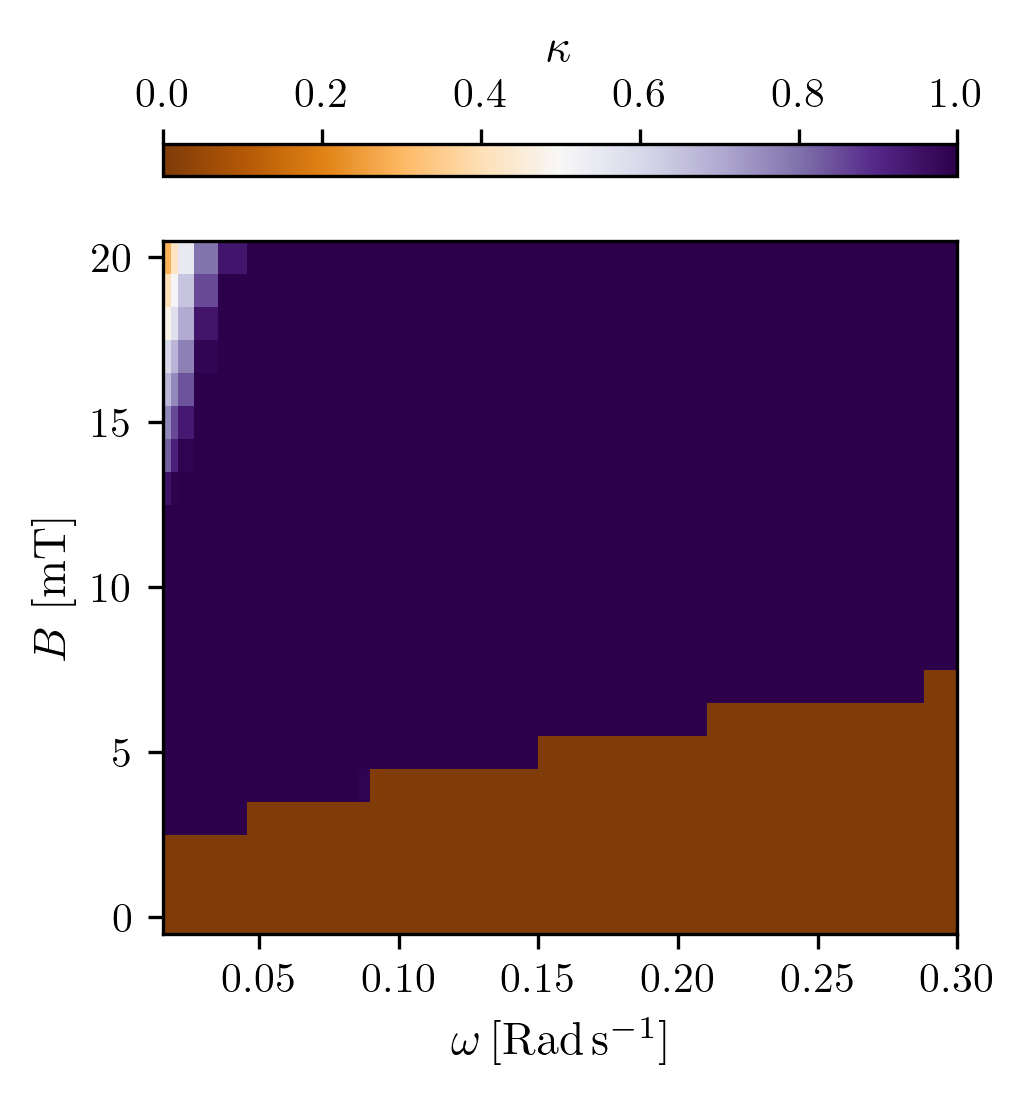

In [12]:
def plot_parameter_map(table):
    grid = table.pivot(index="field", columns="omega", values="kappa").sort_index().sort_index(axis=1)
    assert not grid.isna().any().any()
    width = 246 / 72
    fig = plt.figure(figsize=(width, width), dpi=300)
    gs = fig.add_gridspec(2, 1, height_ratios=[0.045, 1], hspace=0.18)
    cbax, ax = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
    mesh = ax.pcolormesh(grid.columns.to_numpy(), grid.index.to_numpy(), grid.to_numpy(),
                         shading="nearest", cmap="PuOr", vmin=0, vmax=1, rasterized=True)
    ax.set_xlabel(r"$\omega\,[\mathrm{Rad}\,\mathrm{s}^{-1}]$", fontsize=11)
    ax.set_ylabel(r"$B$ [mT]", fontsize=11)
    xmin = grid.columns.min() if FIG6_XLIM[0] is None else FIG6_XLIM[0]
    ax.set_xlim(xmin, FIG6_XLIM[1])
    ax.set_ylim(-0.5, 20.5)
    ax.set_yticks([0, 5, 10, 15, 20])
    cb = fig.colorbar(mesh, cax=cbax, orientation="horizontal", ticks=np.linspace(0, 1, 6))
    cbax.xaxis.set_ticks_position("top")
    cbax.xaxis.set_label_position("top")
    cb.set_label(r"$\kappa$", fontsize=11)
    return fig

fig6 = plot_parameter_map(final)
for suffix in ["pdf", "png"]:
    fig6.savefig(FIGURE_ROOT / f"fig6_0p1K.{suffix}", dpi=300, bbox_inches="tight")
plt.show()

## Saved outputs
All six figures are shown inline and saved as PDF and 300 dpi PNG. `final_observables.csv` contains every sampled field–frequency pair, including points outside the paper axis limits. The provenance file records source campaigns, the reused schematic, snapshots, motion definitions, and the endpoint convention.

In [13]:
(FIGURE_ROOT / "figure_provenance.json").write_text(json.dumps({
    "data_root": str(DATA_ROOT), "campaigns": provenance,
    "temperature_K": 0.1, "size": SIZE,
    "endpoint": "last retained frame, tau - 0.05 s",
    "order_parameter": "mean(abs(staggered charge sum) / (4 * size**2))",
    "omega_units": "rad/s", "figure3_field_mT": FIELD,
    "fig1_source": str(PAPER_ROOT / "fig1.pdf"), "fig1_reused_unchanged": True,
    "selected_times_s": SELECTED_TIMES, "snapshots_tau_s": [100, 4], "snapshot_realization": 1,
    "motion_field_mT": FIELD, "trap_sep_um": TRAP_SEP,
    "crossing_criterion": "absolute initial projected displacement >= d/2, instantaneous fraction",
    "activity_smoothing_frames": 5, "activity_threshold_fraction": 0.08,
    "figure3_xlim": FIG3_XLIM, "figure6_xlim": [final["omega"].min() if FIG6_XLIM[0] is None else FIG6_XLIM[0], FIG6_XLIM[1]],
}, indent=2) + "\n")
print(FIGURE_ROOT)
for path in sorted(FIGURE_ROOT.glob("*")):
    print(path.name)

/home/holo/documents/mnt/frequencygs/repo/data/figures/cold-0p1K
activity_widths.csv
fig1_0p1K.pdf
fig1_0p1K.png
fig2_0p1K.pdf
fig2_0p1K.png
fig3_0p1K_20mT.pdf
fig3_0p1K_20mT.png
fig3ab_0p1K_20mT.pdf
fig3ab_0p1K_20mT.png
fig4_0p1K.pdf
fig4_0p1K.png
fig5_0p1K.pdf
fig5_0p1K.png
fig6_0p1K.pdf
fig6_0p1K.png
figure_provenance.json
final_observables.csv
motion_20mT.json
motion_20mT.parquet
